# 实验02 NumPy、SciPy、Matplotlib 与 pandas 数据处理
学号：20244080318

实验环境：conda虚拟环境 py_exp，安装 numpy、scipy、matplotlib、pandas
提交要求：
1. Markdown解释关键结果；图表带标题、坐标轴标签、图例
2. 随机实验设置固定随机种子
3. 提交前重启内核完整运行全部代码
4. 仅提交：学号_姓名_exp02.ipynb


In [13]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas as pd

# 固定随机种子
np.random.seed(42)

STUDENT_ID = 20244080318
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] py_exp
[学号] 20244080318
[机器指纹] 86062bc25902fa85
[RUN_ID] 20244080318-86062bc25902fa85


## 实验1：NumPy数组、数据类型与索引

任务：
1. 创建整数、浮点数、布尔ndarray，输出dtype、shape、ndim；对比numpy数组与python列表的数据类型差异。
2. `np.arange(12)`生成一维数组，reshape为(3,4)、(2,3,2)；说明reshape元素总数约束条件。
3. 对(3,4)数组索引：取第2行、取1‑3列、取大于6的元素，输出结果与shape。
4. `np.arange(10)`布尔索引：选取小于2或大于7；大于3且小于7；使用`|`、`&`或者`np.logical_or`、`np.logical_and`。
5. 构造两个(2,2)数组，对比`*`、`np.multiply()`逐元素乘法；`@`、`np.matmul()`矩阵乘法，说明两者区别。

> 知识点：
> - numpy数组：所有元素必须是**同一数据类型**；Python列表可以存放任意混合类型对象。
> - reshape：新形状所有维度乘积必须等于数组总元素个数。
> - `*`逐元素相乘；`@`是矩阵数学乘法。


In [14]:
#1 创建不同类型ndarray
arr_int = np.array([1,2,3], dtype=int)
arr_float = np.array([1.1,2.2,3.3], dtype=float)
arr_bool = np.array([True, False, True], dtype=bool)

print("====整数数组====")
print(arr_int, f"dtype={arr_int.dtype}, shape={arr_int.shape}, ndim={arr_int.ndim}")
print("====浮点数数组====")
print(arr_float, f"dtype={arr_float.dtype}, shape={arr_float.shape}, ndim={arr_float.ndim}")
print("====布尔数组====")
print(arr_bool, f"dtype={arr_bool.dtype}, shape={arr_bool.shape}, ndim={arr_bool.ndim}")
print("\n说明：numpy数组全部元素必须为相同类型；Python列表允许存储不同类型对象。")

#2 arange与reshape
a1 = np.arange(12)
a_34 = a1.reshape(3,4)
a_232 = a1.reshape(2,3,2)
print("\n====reshape====")
print("原始：",a1)
print("(3,4):\n",a_34)
print("(2,3,2):\n",a_232)
print("reshape条件：各维度乘积必须等于总元素数目12")

#3 索引
print("\n====索引操作，数组a_34====")
row2 = a_34[1,:]
col1_3 = a_34[:,1:3]
gt6 = a_34[a_34>6]
print("第2行：",row2, "shape", row2.shape)
print("第1‑3列：\n",col1_3, "shape", col1_3.shape)
print(">6元素：",gt6, "shape", gt6.shape)

#4 布尔索引
ar = np.arange(10)
cond1 = np.logical_or(ar <2, ar>7)
cond2 = np.logical_and(ar>3, ar<7)
print("\n====布尔索引====")
print("ar<2 或 ar>7：", ar[cond1])
print("ar>3 且 ar<7：", ar[cond2])

#5 逐元素乘法 vs 矩阵乘法
m1 = np.array([[1,2],[3,4]])
m2 = np.array([[5,6],[7,8]])
elem1 = m1 * m2
elem2 = np.multiply(m1,m2)
mat1 = m1 @ m2
mat2 = np.matmul(m1,m2)
print("\n====乘法对比====")
print("* 逐元素乘法\n",elem1)
print("np.multiply\n",elem2)
print("@矩阵乘法\n",mat1)
print("np.matmul\n",mat2)
print("说明：* / multiply：对应位置元素相乘；@ / matmul：线性代数矩阵乘法。")


====整数数组====
[1 2 3] dtype=int64, shape=(3,), ndim=1
====浮点数数组====
[1.1 2.2 3.3] dtype=float64, shape=(3,), ndim=1
====布尔数组====
[ True False  True] dtype=bool, shape=(3,), ndim=1

说明：numpy数组全部元素必须为相同类型；Python列表允许存储不同类型对象。

====reshape====
原始： [ 0  1  2  3  4  5  6  7  8  9 10 11]
(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
reshape条件：各维度乘积必须等于总元素数目12

====索引操作，数组a_34====
第2行： [4 5 6 7] shape (4,)
第1‑3列：
 [[ 1  2]
 [ 5  6]
 [ 9 10]] shape (3, 2)
>6元素： [ 7  8  9 10 11] shape (5,)

====布尔索引====
ar<2 或 ar>7： [0 1 8 9]
ar>3 且 ar<7： [4 5 6]

====乘法对比====
* 逐元素乘法
 [[ 5 12]
 [21 32]]
np.multiply
 [[ 5 12]
 [21 32]]
@矩阵乘法
 [[19 22]
 [43 50]]
np.matmul
 [[19 22]
 [43 50]]
说明：* / multiply：对应位置元素相乘；@ / matmul：线性代数矩阵乘法。


## 实验2：随机抽样、统计与缺失值

任务：
1. np.random生成1000个正态模拟成绩：均值70，标准差10；`np.clip`限制0‑100；输出样本数、最小、最大、均值、标准差、极差。
2. 从`np.arange(1,11)`不放回抽取5个；对比均匀等概率抽样、按数值大小加权抽样。
3. 演示：随机排列返回新数组（不改动原数组）；原地inplace打乱数组；打印前后原数组观察区别。
4. 将模拟成绩第10、20、30位置设置为`np.nan`；对比普通均值与忽略nan的均值；统计缺失数量；说明nan对普通统计函数的影响。
5. 将带缺失的成绩+序号保存为内存表格变量，供实验4使用，不写入磁盘。


In [15]:
#1 模拟成绩正态分布
scores_raw = np.random.normal(loc=70, scale=10, size=1000)
scores_clip = np.clip(scores_raw, 0, 100)
n_sample = len(scores_clip)
s_min = scores_clip.min()
s_max = scores_clip.max()
s_mean = scores_clip.mean()
s_std = scores_clip.std()
s_range = s_max - s_min
print("====模拟成绩统计====")
print(f"样本数:{n_sample}, min:{s_min:.2f}, max:{s_max:.2f}")
print(f"均值:{s_mean:.2f},标准差:{s_std:.2f},极差:{s_range:.2f}")

#2 不放回抽样
pop = np.arange(1,11)
sample_uniform = np.random.choice(pop, size=5, replace=False)
#加权权重与数值成正比
p_weight = pop / pop.sum()
sample_weighted = np.random.choice(pop, size=5, replace=False, p=p_weight)
print("\n====抽样====")
print("均匀不放回抽样：", sample_uniform)
print("按数值加权不放回抽样：", sample_weighted)

#3 随机排列 vs原地打乱
arr_demo = np.arange(8)
arr_copy = arr_demo.copy()
permuted = np.random.permutation(arr_copy)
print("\n====permutation不修改原数组====")
print("原数组",arr_copy)
print("返回新排列",permuted)

arr_inplace = np.arange(8)
print("\n====shuffle原地打乱====")
print("shuffle前",arr_inplace)
np.random.shuffle(arr_inplace)
print("shuffle后",arr_inplace)

#4 加入nan缺失值
scores_nan = scores_clip.copy()
#索引第10,20,30（下标从0开始，9,19,29）
scores_nan[[9,19,29]] = np.nan
mean_normal = np.mean(scores_nan)
mean_nanignore = np.nanmean(scores_nan)
nan_count = np.sum(np.isnan(scores_nan))
print("\n====缺失值处理====")
print(f"普通np.mean(含nan): {mean_normal} （全部变成nan）")
print(f"np.nanmean忽略缺失值: {mean_nanignore:.2f}")
print(f"缺失值数量：{nan_count}")
print("说明：普通np.mean遇到np.nan结果直接返回nan；必须使用nanmean/nanmax等系列函数跳过缺失。")

#5 内存表格变量（不写磁盘）
idx_arr = np.arange(len(scores_nan))
exp2_table = {"index":idx_arr, "score":scores_nan}
print("\nexp2_table已保存在内存，用于后续实验")


====模拟成绩统计====
样本数:1000, min:37.59, max:100.00
均值:70.18,标准差:9.76,极差:62.41

====抽样====
均匀不放回抽样： [ 4  9  2  6 10]
按数值加权不放回抽样： [10  2  8  9  6]

====permutation不修改原数组====
原数组 [0 1 2 3 4 5 6 7]
返回新排列 [1 0 6 4 2 7 3 5]

====shuffle原地打乱====
shuffle前 [0 1 2 3 4 5 6 7]
shuffle后 [2 0 6 4 1 5 7 3]

====缺失值处理====
普通np.mean(含nan): nan （全部变成nan）
np.nanmean忽略缺失值: 70.20
缺失值数量：3
说明：普通np.mean遇到np.nan结果直接返回nan；必须使用nanmean/nanmax等系列函数跳过缺失。

exp2_table已保存在内存，用于后续实验


## 实验3：SciPy数值计算与Matplotlib可视化

任务：
1. 使用`scipy.linalg.solve()`求解方程组
$$
\begin{cases}
3x + y = 9\\
x + 2y = 8
\end{cases}
$$
numpy代入验证解。

2. `scipy.optimize.root()`求解方程 $x^2-2=0$，分别求正根、负根，设置不同初始猜测；打印求解状态与结果，验证函数输出接近0。

3. `scipy.optimize.minimize()`求 $f(x)=x^2+x+2$ 最小值；输出极小点、函数值，对比解析解。解析：$x=-0.5$，最小值 $1.75$。

4. 生成两组样本，每组100个：组1 N(0,1)，组2 N(1,1)；固定随机种子；`scipy.stats.ttest_ind()`独立样本t检验；输出t统计量、p值；0.05显著性水平下判断是否存在显著差异。

5. matplotlib绘图：
   - 实验2有效成绩绘制直方图、箱线图；
   - 同一坐标系绘制 $y=x,\ y=x^2,\ y=x^3$，$0\le x \le5$；
   - 每张图要有标题、坐标轴标签、图例；图片直接在notebook展示，不保存文件。


====1.线性方程组求解====
解 x=2.000, y=3.000
代入A@sol： [9. 8.] 与b对比 [9 8]

====2.求根 x^2‑2=0====
正根初值x0=2：成功 True 根 [1.41421356] f(x) [8.8817842e-16]
负根初值x0=-2：成功 True 根 [-1.41421356] f(x) [8.8817842e-16]

====3.函数极小值====
极小点x: [-0.50000001] 函数值 1.75
解析解 x=-0.5，最小值1.75

====4.t检验====
t统计量=-8.5515, p‑value=0.0000
p<0.05，拒绝原假设，两组均值存在显著差异


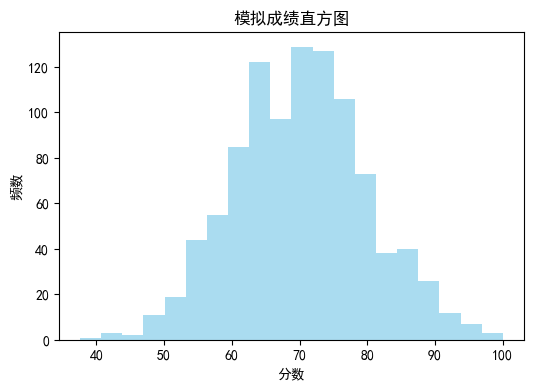

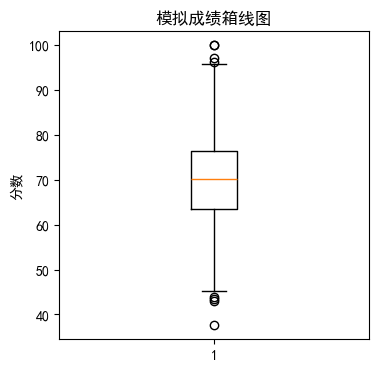

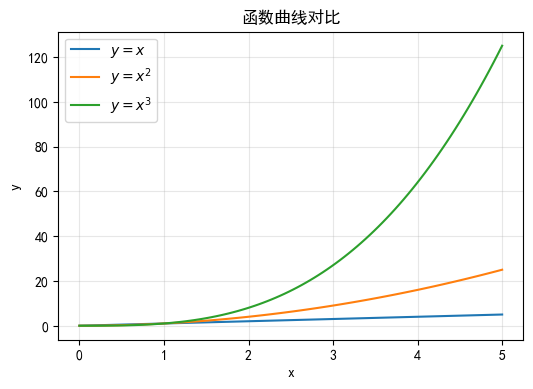

In [16]:
from scipy import linalg, optimize, stats

#1 解线性方程组
A = np.array([[3,1],[1,2]])
b = np.array([9,8])
sol = linalg.solve(A,b)
print("====1.线性方程组求解====")
print(f"解 x={sol[0]:.3f}, y={sol[1]:.3f}")
#代入验证
print("代入A@sol：", A @ sol, "与b对比", b)

#2 root求 x^2‑2=0
def f_root(x):
    return x**2 - 2
res_pos = optimize.root(f_root, x0=2)
res_neg = optimize.root(f_root, x0=-2)
print("\n====2.求根 x^2‑2=0====")
print("正根初值x0=2：成功",res_pos.success, "根",res_pos.x, "f(x)",f_root(res_pos.x))
print("负根初值x0=-2：成功",res_neg.success, "根",res_neg.x, "f(x)",f_root(res_neg.x))

#3 minimize求 f=x²+x+2
def f_min(x):
    return x**2 + x + 2
res_min = optimize.minimize(f_min, x0=0)
print("\n====3.函数极小值====")
print("极小点x:", res_min.x, "函数值", res_min.fun)
print("解析解 x=-0.5，最小值1.75")

#4 独立样本t检验
np.random.seed(42)
s1 = np.random.normal(loc=0,scale=1,size=100)
s2 = np.random.normal(loc=1,scale=1,size=100)
t_result = stats.ttest_ind(s1,s2)
print("\n====4.t检验====")
print(f"t统计量={t_result.statistic:.4f}, p‑value={t_result.pvalue:.4f}")
alpha = 0.05
if t_result.pvalue < alpha:
    print(f"p<{alpha}，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p≥{alpha}，不能拒绝原假设，无充分证据说明均值不同")

#5 matplotlib绘图
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

#直方图
plt.figure(figsize=(6,4))
valid_score = scores_clip[~np.isnan(scores_clip)]
plt.hist(valid_score, bins=20, color="skyblue", alpha=0.7)
plt.title("模拟成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")
plt.show()

#箱线图
plt.figure(figsize=(4,4))
plt.boxplot(valid_score)
plt.title("模拟成绩箱线图")
plt.ylabel("分数")
plt.show()

#函数曲线 y=x x² x³
x_line = np.linspace(0,5,100)
y1 = x_line
y2 = x_line**2
y3 = x_line**3
plt.figure(figsize=(6,4))
plt.plot(x_line,y1,label="$y=x$")
plt.plot(x_line,y2,label="$y=x^2$")
plt.plot(x_line,y3,label="$y=x^3$")
plt.title("函数曲线对比")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 实验4：pandas Series、DataFrame与内存CSV读写

原始模拟数据：
```python
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}


In [17]:

import pandas as pd

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

# 创建DataFrame
df = pd.DataFrame(records)
# 将Name设置为行索引
df = df.set_index("Name")

# 新增两列：三科总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("===行索引===")
print(df.index.tolist())
print("\n===列名===")
print(df.columns.tolist())
print("\n===前3行数据===")
print(df.head(3))
print("\n===基本统计信息describe()===")
print(df.describe())


===行索引===
['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']

===列名===
['Group', 'Math', 'English', 'Python', 'Total', 'Average']

===前3行数据===
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

===基本统计信息describe()===
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


任务2：使用 loc（标签索引）、iloc（数字位置索引）读取Carol记录；筛选平均分不低于80分的学生。
- loc：**按索引标签名字取数据**
- iloc：**按数字下标位置取数据，从0开始**


In [18]:
# loc：直接写索引名字Carol
print("====loc读取Carol====")
print(df.loc["Carol"])

# iloc：先查找Carol对应的数字行号
carol_pos = df.index.get_loc("Carol")
print(f"\nCarol的行下标位置：{carol_pos}")
print("====iloc读取Carol====")
print(df.iloc[carol_pos])

# 筛选平均分 >= 80
high_avg_student = df[df["Average"] >= 80]
print("\n====平均分大于等于80的学生====")
print(high_avg_student)


====loc读取Carol====
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

Carol的行下标位置：2
====iloc读取Carol====
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

====平均分大于等于80的学生====
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


任务3：
- `axis=0`：沿着**行方向压缩，求每一列的均值（各科平均分）**
- `axis=1`：沿着**列方向压缩，求每一行的均值（每个学生平均分）**


In [19]:
score_cols = ["Math", "English", "Python"]
# axis=0 每一列（科目）的均值
col_mean = df[score_cols].mean(axis=0)
# axis=1 每一行（学生）的均值
row_mean = df[score_cols].mean(axis=1)

print("===各科列均值 axis=0===")
print(col_mean)
print("\n===每个学生行均值 axis=1===")
print(row_mean)


===各科列均值 axis=0===
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

===每个学生行均值 axis=1===
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


任务4：
1. `apply(max,axis=1)`：按行apply，取每个学生三科最高分
2. `agg()`：一次性对多列执行多个统计函数 min mean max
3. `rank()`：对数学成绩排名，`ascending=False`分数越高名次数字越小


In [20]:
# apply，每行取最大分数
df["max_score"] = df[score_cols].apply(max, axis=1)

# agg聚合，同时求min mean max
agg_result = df[score_cols].agg(["min", "mean", "max"])

# rank数学成绩排名，降序，高分第一名
df["math_rank"] = df["Math"].rank(ascending=False)

print("===每名学生三科最高分===")
print(df[["max_score"]])
print("\n===agg每科min mean max===")
print(agg_result)
print("\n===数学成绩排名===")
print(df[["Math","math_rank"]])


===每名学生三科最高分===
       max_score
Name            
Alice         95
Bob           80
Carol         91
David         73
Eva           92
Frank         84

===agg每科min mean max===
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

===数学成绩排名===
       Math  math_rank
Name                  
Alice    88        2.0
Bob      72        5.0
Carol    91        1.0
David    65        6.0
Eva      79        4.0
Frank    84        3.0


任务5：
1. groupby("Group")按照A/B分组
2. size()统计每组人数；mean()统计每组三科平均分
3. transform("mean")：**把分组计算的结果，映射回原始每一行**，新增本组Python科目平均分


In [21]:
group = df.groupby("Group")

print("====每组人数 group.size()====")
print(group.size())

print("\n====每组三科平均分====")
print(group[score_cols].mean())

# transform 将分组计算的Python平均分回填到每一行
df["group_python_mean"] = group["Python"].transform("mean")
print("\n===增加本组Python平均分列===")
print(df[["Group","Python","group_python_mean"]])


====每组人数 group.size()====
Group
A    3
B    3
dtype: int64

====每组三科平均分====
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

===增加本组Python平均分列===
      Group  Python  group_python_mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


任务6 filter：保留组内Python科目平均分≥80的全部学生。
filter传入lambda，输入是整个分组子DataFrame；满足条件就保留该分组全部行。


In [22]:
# group对象调用filter，保留组Python平均分>=80
df_filter_group = group.filter(lambda sub_df: sub_df["Python"].mean() >=80)
print("===Python组平均分>=80的分组数据===")
print(df_filter_group)


===Python组平均分>=80的分组数据===
      Group  Math  English  Python  Total    Average  max_score  math_rank  \
Name                                                                         
Alice     A    88       90      95    273  91.000000         95        2.0   
Bob       A    72       68      80    220  73.333333         80        5.0   
Carol     B    91       85      89    265  88.333333         91        1.0   
David     B    65       73      70    208  69.333333         73        6.0   
Eva       A    79       92      86    257  85.666667         92        4.0   
Frank     B    84       77      82    243  81.000000         84        3.0   

       group_python_mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


任务7：计算三科协方差矩阵、皮尔逊相关系数矩阵。

- 协方差：符号代表变化方向；正数：两个科目成绩同向变化。
- 皮尔逊相关系数：取值[-1,1]；越接近1强正相关，越接近‑1强负相关，接近0无线性相关。


In [23]:
cov_matrix = df[score_cols].cov()
corr_matrix = df[score_cols].corr()

print("====协方差矩阵====")
print(cov_matrix)
print("\n====皮尔逊相关系数矩阵====")
print(corr_matrix)

# 选一组做文字解释
math_eng_corr = corr_matrix.loc["Math","English"]
print(f"\nMath与English相关系数：{math_eng_corr:.3f}")
print("解释：相关系数为正数，说明数学高的同学英语也倾向较高，存在正线性相关。")


====协方差矩阵====
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

====皮尔逊相关系数矩阵====
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000

Math与English相关系数：0.654
解释：相关系数为正数，说明数学高的同学英语也倾向较高，存在正线性相关。
